## Imports and Tokens

In [4]:
from matplotlib import pyplot as plt
import pandas as pd
import json
import random
from src.utils.entsoe_client import fetch_and_save_spot_prices
import json


# Define the API tokens
# Personal renewables.ninja API token
with open(r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\secrets.json") as f:
    secrets = json.load(f)

ninja_token = secrets.get("ninja_token")
entsoe_api_key = secrets.get("entsoe_api_key")


## Data Loading and Cleaning

#### Spot data - ENTSOE API

In [5]:
# Spot market data 2019
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2019-01-01'
end_date = '2019-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)

# Spot market data 2020
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2020-01-01'
end_date = '2020-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)

# Load the data as a pandas DataFrame
spot_prices_2019 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2019.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2019['Price ct/KWH'] = spot_prices_2019['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

print(spot_prices_2019.head())
print("Average price 2019: ", spot_prices_2019['Price ct/KWH'].mean())

#2020
spot_prices_2020 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2020.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2020['Price ct/KWH'] = spot_prices_2020['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

#print("Average price 2020: ", spot_prices_2020['Price ct/KWH'].mean())

spot_prices_2020

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_32224\1402570545.py:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2019 = data = pd.read_csv(


           Date (CET)  Price (€/MWh)  Price ct/KWH
0 2019-01-01 00:00:00          28.32         2.832
1 2019-01-01 01:00:00          10.07         1.007
2 2019-01-01 02:00:00          -4.08        -0.408
3 2019-01-01 03:00:00          -9.91        -0.991
4 2019-01-01 04:00:00          -7.41        -0.741
Average price 2019:  3.7680148809523812


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_32224\1402570545.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2020 = data = pd.read_csv(


,Date (CET),Price (€/MWh),Price ct/KWH
0,2020-01-01 00:00:00,41.88,4.188
1,2020-01-01 01:00:00,38.60,3.860
2,2020-01-01 02:00:00,36.55,3.655
3,2020-01-01 03:00:00,32.32,3.232
4,2020-01-01 04:00:00,30.85,3.085
...,...,...,...
8755,2020-12-30 19:00:00,53.60,5.360
8756,2020-12-30 20:00:00,52.38,5.238
8757,2020-12-30 21:00:00,46.88,4.688
8758,2020-12-30 22:00:00,43.22,4.322


#### Electricity Prices over the years:  
Source: https://www.bdew.de/service/daten-und-grafiken/bdew-strompreisanalyse/
![image.png](attachment:image.png)

In [17]:
# Load the data from the CSV file
electricity_prices_df = pd.read_csv('data/electricity_prices_yearly/electricity_prices_yearly2014_2024.csv', delimiter=',', decimal='.', parse_dates=['Year'])

# Year als Jahreszahl
electricity_prices_df['Year'] = pd.to_datetime(electricity_prices_df['Year']).dt.year




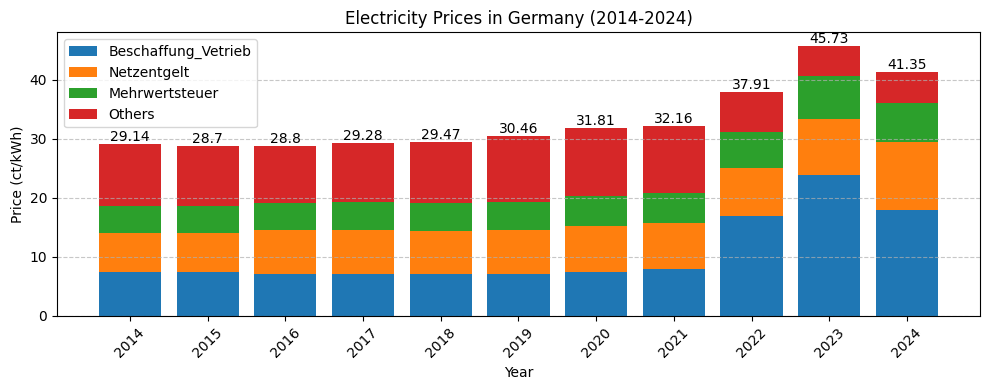

In [18]:
# Plot the data as a stacked bar chart
plt.figure(figsize=(10,4))
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Beschaffung_Vetrieb'], label='Beschaffung_Vetrieb')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Netzentgelt'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'], label='Netzentgelt')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Mehrwertsteuer'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'], label='Mehrwertsteuer')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Sonstige'],bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'] + electricity_prices_df['Mehrwertsteuer'], label='Others')
plt.xlabel('Year')
plt.ylabel('Price (ct/kWh)')
for i in range(len(electricity_prices_df)):
    plt.text(electricity_prices_df['Year'][i], electricity_prices_df['Summe'][i] + 0.5, str(electricity_prices_df['Summe'][i]), ha='center') #add values
plt.title('Electricity Prices in Germany (2014-2024)')
plt.xticks(electricity_prices_df['Year'], rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### Load Household data

- filtered_df = Data of all households in 2019
- filtered_df_test = Data of all households in 2020

In [ ]:
#Load pickle into dataframe
hh_path = r"local_input_data\1920 Final Data w. Additional Features HH Hourly Agg.pkl"
start_date = '2019-01-01'
end_date = '2019-12-31'
start_date_test = '2020-01-01'
end_date_test = '2020-12-31'
keyword = 'SFH' # Single Family Households

data_allhouseholds = pd.read_pickle(hh_path)
mask_model = (data_allhouseholds.index >= start_date) & (data_allhouseholds.index < end_date)
mask_test = (data_allhouseholds.index >= start_date_test) & (data_allhouseholds.index < end_date_test)


##### 2019

In [5]:
data_allhouseholds_model = data_allhouseholds.loc[mask_model]

# Extract columns that contain the keyword in their name
filtered_df = data_allhouseholds_model.filter(like=keyword)
filtered_df = filtered_df.drop(columns=['SFH34_P_TOT']) # TODO: SHOW WHY Household 34 is shit

# turn unit to kWh
filtered_df = filtered_df/1000

print("Number of households: ", len(filtered_df.columns))
filtered_df.head()


Number of households:  21


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:00+00:00,0.161493,0.378307,0.555783,0.472945,0.276283,0.141515,1.263900,0.138280,0.167612,0.204542,...,0.187705,0.278985,0.095981,0.091195,0.130055,0.183680,0.172490,0.341785,0.552966,0.137806
2019-01-01 01:00:00+00:00,0.201888,0.379044,0.446765,0.303302,0.254865,0.137292,1.251248,0.109699,0.171209,0.207164,...,0.198733,0.309711,0.097085,0.177395,0.111404,0.080881,0.115421,0.335813,0.326356,0.146449
2019-01-01 02:00:00+00:00,0.156627,0.381565,0.301362,0.142379,0.198773,0.133582,1.121481,0.072142,0.159650,0.214528,...,0.192340,0.399156,0.102519,0.236366,0.118093,0.119899,0.145594,0.211437,0.263901,0.156046
2019-01-01 03:00:00+00:00,0.155399,0.427539,0.307746,0.152653,0.241786,0.147410,0.990431,0.102894,0.124849,0.194947,...,0.224510,0.149937,0.096335,0.186000,0.116369,0.077734,0.112445,0.146979,0.303394,0.176267
2019-01-01 04:00:00+00:00,0.112611,0.309020,0.326347,0.208406,0.165343,0.126375,0.314959,0.091286,0.175570,0.283466,...,0.182807,0.186482,0.095063,0.171690,0.122021,0.076919,0.078177,0.141085,0.290612,0.286422


##### 2020

In [6]:
data_allhouseholds_test = data_allhouseholds.loc[mask_test]

# Extract columns that contain the keyword in their name
filtered_df_test = data_allhouseholds_test.filter(like=keyword)
filtered_df_test = filtered_df_test.drop(columns=['SFH34_P_TOT'])

# turn unit to kWh
filtered_df_test = filtered_df_test/1000

print("Number of households: ", len(filtered_df_test.columns))

filtered_df_test

Number of households:  21


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,0.163916,0.373391,0.426055,0.175637,0.880133,0.147927,1.028024,0.240754,0.093248,0.596717,...,0.276218,0.344925,0.088926,0.599022,0.111477,0.150296,0.199717,0.149463,0.404039,0.151883
2020-01-01 01:00:00+00:00,0.096884,0.433742,0.414172,0.132504,0.568079,0.142868,0.659489,0.181140,0.120597,1.297585,...,0.233408,0.200887,0.095167,0.585296,0.096038,0.081426,0.206756,0.157918,0.434017,0.151909
2020-01-01 02:00:00+00:00,0.207420,0.455052,0.373124,0.198556,0.641215,0.136044,0.358423,0.109398,0.137314,1.125870,...,0.193405,0.175490,0.103124,0.578868,0.098231,0.083770,0.138144,0.159315,0.546359,0.171845
2020-01-01 03:00:00+00:00,0.109694,0.377600,0.365616,0.150788,0.538791,0.135456,0.349706,0.102048,0.093597,0.299468,...,0.214475,0.146496,0.093065,0.255038,0.100640,0.060413,0.129610,0.138526,0.334807,0.128404
2020-01-01 04:00:00+00:00,0.193015,0.277767,0.374640,0.100247,0.368989,0.145098,0.348721,0.110583,0.123097,0.319027,...,0.205340,0.220397,0.076818,0.161516,0.108735,0.090928,0.077703,0.139926,0.224035,0.150912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-30 19:00:00+00:00,0.285882,1.288372,0.487239,0.444430,0.621300,0.287039,1.417525,0.368618,0.992046,0.363517,...,0.299486,1.921150,0.119291,0.597287,0.373720,0.445905,0.541438,0.217190,1.002722,0.271178
2020-12-30 20:00:00+00:00,0.177044,0.443794,0.510834,0.503695,0.597298,0.328044,0.874725,0.298788,0.866079,0.226329,...,0.297135,0.430116,0.114994,0.569243,0.184183,0.223751,0.422432,0.210398,0.553453,0.291510
2020-12-30 21:00:00+00:00,0.240316,0.433245,0.352619,0.454367,0.504256,0.287266,1.038879,0.294333,0.427432,0.178664,...,0.209374,0.404800,0.079628,0.580204,0.197486,0.110087,0.342846,0.187408,0.559419,0.214913


# Models

## 1. Model: Standardlastprofil: 
- Load data: Datensatz: SLP 2019 der Stadtwerke Groß-Gerau Versorgung GmbH: https://ggv-energie.de/cms/netz/allgemeine-daten/netzbilanzierung-download-aller-profile.php
  - Datensatz enthält Standardlastprofil eines typischen Einfamilien Haushalt (H00)
- Vorhersage für 2020, auf Basis des Standardlastprofils
  - Standard Werktag auf Basis vom 
  - Standard Wochenende
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)
- Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
- Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten



### Load SLP data and normalize to 3000kwh

Load Data

In [7]:
file_path = r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\data\slp\GGV_SLP_1000_MWh_2019_01.xlsx"
sheet_name = "15Min - SLP 2019" # Single Load Profile 2019

data_15min_slp_2019 = pd.read_excel(file_path, sheet_name=sheet_name)
data_15min_slp_2019.head() 

,Messwert-Nr.,Wochentag,Datum,Zeitstempel von,Zeitstempel bis,MP von,MP bis,H00 [kW],H00 [kWh]
0,1,2,2019-01-01,2019-01-01 00:00:00,2019-01-01 00:15:00,00:00,00:15,145.200,36.300
1,2,2,2019-01-01,2019-01-01 00:15:00,2019-01-01 00:30:00,00:15,00:30,140.112,35.028
2,3,2,2019-01-01,2019-01-01 00:30:00,2019-01-01 00:45:00,00:30,00:45,135.720,33.930
3,4,2,2019-01-01,2019-01-01 00:45:00,2019-01-01 01:00:00,00:45,01:00,130.732,32.683
4,5,2,2019-01-01,2019-01-01 01:00:00,2019-01-01 01:15:00,01:00,01:15,127.236,31.809


Data Prepapration

In [8]:
data_15min_slp_2019.drop(columns=['Messwert-Nr.','MP von', 'MP bis'], inplace=True)

In [9]:
#Fasse Zeitstempel pro Stunde zusammen und summiere H00 [kW] in neuer df
data_15min_slp_2019['Time'] = data_15min_slp_2019['Zeitstempel von'].dt.floor('h')

data_slp_hourly_2019 = data_15min_slp_2019.groupby('Time').agg({'H00 [kW]': 'sum'}).reset_index()
data_slp_hourly_2019['H00 [kWh]'] = data_slp_hourly_2019['H00 [kW]'] / 4 
#add 'Wochentag'
data_slp_hourly_2019['Weekday'] = data_slp_hourly_2019['Time'].dt.day_name()

#add Arbeitstag oder Wochenende als neue Spalte
data_slp_hourly_2019['Weekend'] = data_slp_hourly_2019['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)

#add Hour and save as int
data_slp_hourly_2019['Hour'] = data_slp_hourly_2019['Time'].dt.time
data_slp_hourly_2019['Hour'] = data_slp_hourly_2019['Hour'].apply(lambda x: x.hour)

#Normalizing the values to a "average household" with 3000 kWh  
data_slp_hourly_2019['H00_Norm [kWh]'] = data_slp_hourly_2019['H00 [kWh]'] /data_slp_hourly_2019['H00 [kWh]'].sum()*3000

data_slp_hourly_2019

,Time,H00 [kW],H00 [kWh],Weekday,Weekend,Hour,H00_Norm [kWh]
0,2019-01-01 00:00:00,551.764,137.941,Tuesday,0,0,0.413823
1,2019-01-01 01:00:00,492.584,123.146,Tuesday,0,1,0.369438
2,2019-01-01 02:00:00,448.376,112.094,Tuesday,0,2,0.336282
3,2019-01-01 03:00:00,418.236,104.559,Tuesday,0,3,0.313677
4,2019-01-01 04:00:00,386.208,96.552,Tuesday,0,4,0.289656
...,...,...,...,...,...,...,...
8754,2019-12-31 19:00:00,656.444,164.111,Tuesday,0,19,0.492333
8755,2019-12-31 20:00:00,574.216,143.554,Tuesday,0,20,0.430662
8756,2019-12-31 21:00:00,557.048,139.262,Tuesday,0,21,0.417786
8757,2019-12-31 22:00:00,640.876,160.219,Tuesday,0,22,0.480657


### Prediction for 2020
auf Basis des Standardlastprofils
  - Standard Werktag berechnen 
  - Standard Wochenende
  - Diese WErte auf Prediciton profil von 2020 übertragen.
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)


In [10]:
#Calculate an average Weekday (Monday - Fridaay means Weekend == 0)
weekday_data = data_slp_hourly_2019[data_slp_hourly_2019['Weekend'] == 0]

average_weekday = weekday_data.groupby('Hour').agg({'H00_Norm [kWh]': 'mean'}).reset_index()

average_weekday.head()

,Hour,H00_Norm [kWh]
0,0,0.263477
1,1,0.231250
2,2,0.221361
3,3,0.219777
4,4,0.227036


Calculate an average Weekday (Monday - Fridaay means Weekend == 0)

In [11]:
#Calculate an average Weekday (Saturday/Sunday means Weekend == 1

weekendday_data = data_slp_hourly_2019[data_slp_hourly_2019['Weekend'] == 1]
average_weekendday = weekendday_data.groupby('Hour').agg({'H00_Norm [kWh]': 'mean'}).reset_index()

average_weekendday.head()

,Hour,H00_Norm [kWh]
0,0,0.279139
1,1,0.241221
2,2,0.226147
3,3,0.219243
4,4,0.217916


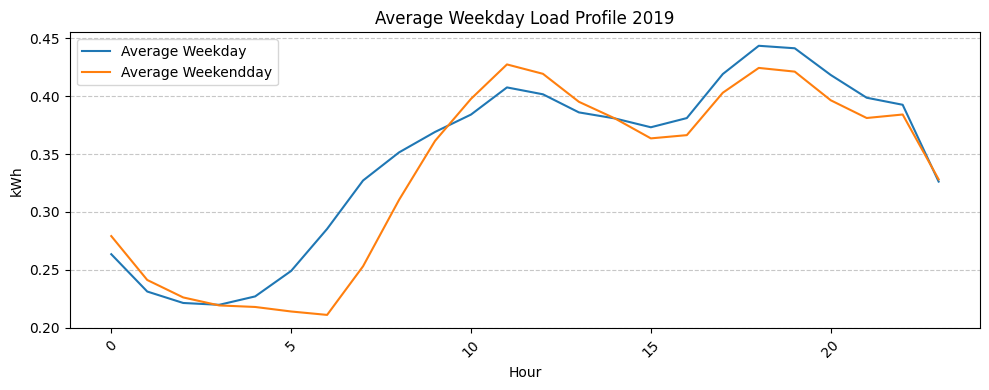

In [12]:
#Plots
#Plot
plt.figure(figsize=(10,4))
plt.plot(average_weekday['Hour'], average_weekday['H00_Norm [kWh]'], label='Average Weekday')
plt.plot(average_weekendday['Hour'], average_weekendday['H00_Norm [kWh]'], label='Average Weekendday')
plt.xlabel('Hour')
plt.ylabel('kWh')
plt.title('Average Weekday Load Profile 2019')
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


#### Prediciton profil von 2020 erstellen
- range aufstellen
- if Weekday -> average_weekday matchen zu Kalender auf Basis von Stunden
- if Weekend -> average_weekendday matchen zu Kalender auf Basis von Stunden

In [50]:
# Define the target full-year date range
start_date_2020 = '2020-01-01'
end_date_2020 = '2020-12-31'
date_range = pd.date_range(start=start_date_2020, end=end_date_2020, freq='h', tz='UTC') # hourly data

In [51]:
# Create a DataFrame with the full-year date range
model1_prediciton_2020 = pd.DataFrame(index=date_range)

# add Day informations
model1_prediciton_2020['Hour'] = model1_prediciton_2020.index.hour
model1_prediciton_2020['Weekday'] = model1_prediciton_2020.index.day_name()
model1_prediciton_2020['Weekend'] = model1_prediciton_2020['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)

model1_prediciton_2020['H00_predicted [kWh]']=0
model1_prediciton_2020 = model1_prediciton_2020[:-1] #delete last row (0Uhr)

model1_prediciton_2020.head()

,Hour,Weekday,Weekend,H00_predicted [kWh]
2020-01-01 00:00:00+00:00,0,Wednesday,0,0
2020-01-01 01:00:00+00:00,1,Wednesday,0,0
2020-01-01 02:00:00+00:00,2,Wednesday,0,0
2020-01-01 03:00:00+00:00,3,Wednesday,0,0
2020-01-01 04:00:00+00:00,4,Wednesday,0,0


In [14]:
# add information for model1_prediciton_2020['H00_predicted [kWh]']. If Weekday == 0 then take average_weekday else average_weekendday and match with Hour
for index, row in model1_prediciton_2020.iterrows():
    if row['Weekend'] == 0:
        model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekday[average_weekday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]
    else:
        model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekendday[average_weekendday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_27684\2267906313.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.2634770519382463' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekday[average_weekday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]


In [130]:
model1_prediciton_2020

,Hour,Weekday,Weekend,H00_predicted [kWh]
2020-01-01 00:00:00+00:00,0,Wednesday,0,0.263477
2020-01-01 01:00:00+00:00,1,Wednesday,0,0.231250
2020-01-01 02:00:00+00:00,2,Wednesday,0,0.221361
2020-01-01 03:00:00+00:00,3,Wednesday,0,0.219777
2020-01-01 04:00:00+00:00,4,Wednesday,0,0.227036
...,...,...,...,...
2020-12-30 19:00:00+00:00,19,Wednesday,0,0.441350
2020-12-30 20:00:00+00:00,20,Wednesday,0,0.418301
2020-12-30 21:00:00+00:00,21,Wednesday,0,0.398629
2020-12-30 22:00:00+00:00,22,Wednesday,0,0.392547


### Test the model	
- Vergleich mit realem Datensatz von allen Haushalten. Berechne MAPE
- Preisberechnugn für 2020

In [15]:
# Define actual_load_profile2020
actual_load_profile2020 = filtered_df_test

# Display the actual load profile for 2020
actual_load_profile2020.head()

#Normalize to 3000 kWh
for column in actual_load_profile2020.columns:
    actual_load_profile2020[column] = actual_load_profile2020[column] / actual_load_profile2020[column].sum() * 3000

# Display the actual load profile for 2020
actual_load_profile2020.head()

,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,0.235083,0.338549,0.421355,0.165795,0.536347,0.130392,1.260980,0.312827,0.100835,0.529366,...,0.316237,0.288901,0.238178,0.565123,0.230555,0.195297,0.216712,0.168074,0.314421,0.188607
2020-01-01 01:00:00+00:00,0.138948,0.393269,0.409602,0.125080,0.346184,0.125933,0.808933,0.235367,0.130411,1.151129,...,0.267225,0.168259,0.254894,0.552174,0.198624,0.105806,0.224350,0.177582,0.337750,0.188640
2020-01-01 02:00:00+00:00,0.297474,0.412591,0.369007,0.187430,0.390752,0.119917,0.439644,0.142148,0.148487,0.998795,...,0.221426,0.146986,0.276205,0.546109,0.203159,0.108852,0.149899,0.179153,0.425174,0.213396
2020-01-01 03:00:00+00:00,0.157319,0.342366,0.361583,0.142339,0.328336,0.119399,0.428951,0.132597,0.101213,0.265667,...,0.245548,0.122702,0.249265,0.240605,0.208143,0.078502,0.140639,0.155775,0.260545,0.159452
2020-01-01 04:00:00+00:00,0.276814,0.251848,0.370506,0.094630,0.224859,0.127898,0.427743,0.143687,0.133114,0.283019,...,0.235090,0.184600,0.205749,0.152376,0.224884,0.118153,0.084315,0.157349,0.174343,0.187402


In [16]:
# NMAE
def calculate_nmae(actual_df, predicted_df):
    """
    Calculate the Normalized Mean Absolute Error (NMAE) between actual and predicted values.

    Parameters:
    - actual_df (pd.DataFrame or pd.Series): The DataFrame or Series containing actual values.
    - predicted_df (pd.DataFrame or pd.Series): The DataFrame or Series containing predicted values.

    Returns:
    - float: The NMAE value as a percentage.
    """
    if not actual_df.index.equals(predicted_df.index):
        raise ValueError("The indices of actual_df and predicted_df must match.")
    absolute_errors = abs(actual_df - predicted_df)
    mae = absolute_errors.mean() # Compute the Mean Absolute Error (MAE)
    nmae = mae / actual_df.mean() # Compute the Normalized Mean Absolute Error (NMAE)
    return 100 * nmae

# Calculate NMAE for each SFH column
nmae_results_m1 = {}
for column in actual_load_profile2020.columns:
    nmae_m1 = calculate_nmae(actual_load_profile2020[column], model1_prediciton_2020['H00_predicted [kWh]'])
    nmae_results_m1[column] = nmae_m1
    print(f"NMAE for {column}: {nmae_m1:.2f} %")
nmae_average_m1 = sum(nmae_results_m1.values())/len(nmae_results_m1)
nmae_average_m1


NMAE for SFH3_P_TOT: 58.07 %
NMAE for SFH4_P_TOT: 39.39 %
NMAE for SFH5_P_TOT: 50.62 %
NMAE for SFH7_P_TOT: 50.45 %
NMAE for SFH9_P_TOT: 62.75 %
NMAE for SFH12_P_TOT: 67.07 %
NMAE for SFH14_P_TOT: 60.65 %
NMAE for SFH16_P_TOT: 69.87 %
NMAE for SFH18_P_TOT: 71.88 %
NMAE for SFH19_P_TOT: 43.41 %
NMAE for SFH20_P_TOT: 49.42 %
NMAE for SFH21_P_TOT: 37.17 %
NMAE for SFH22_P_TOT: 48.06 %
NMAE for SFH27_P_TOT: 34.20 %
NMAE for SFH28_P_TOT: 57.14 %
NMAE for SFH29_P_TOT: 52.29 %
NMAE for SFH30_P_TOT: 61.87 %
NMAE for SFH32_P_TOT: 48.67 %
NMAE for SFH36_P_TOT: 54.38 %
NMAE for SFH38_P_TOT: 33.25 %
NMAE for SFH39_P_TOT: 35.44 %


np.float64(51.71638548702025)

#### Cost Comparison
- price calculation 2020 (dynamic, static prices)
- Predicted costs (dynamic, static prices)
- actual costs (dynamic, static prices)
- Auswertung

In [17]:
spot_prices_2020
#use 'Date (CET' as index
spot_prices_2020.set_index('Date (CET)', inplace=True)
spot_prices_2020


,Price (€/MWh),Price ct/KWH
Date (CET),,
2020-01-01 00:00:00,41.88,4.188
2020-01-01 01:00:00,38.60,3.860
2020-01-01 02:00:00,36.55,3.655
2020-01-01 03:00:00,32.32,3.232
2020-01-01 04:00:00,30.85,3.085
...,...,...
2020-12-30 19:00:00,53.60,5.360
2020-12-30 20:00:00,52.38,5.238
2020-12-30 21:00:00,46.88,4.688


In [18]:
# Preisberechnung

# Define the missing variables # TODO: Replace with actual values
consumption_dependent_fixed_costs = 19.71  # ct per KwH 2024 value Tibber - Example value, replace with actual value
Consumption_independent_base_price = 15.73  # €/Monat - 2024 value Tibber - Example value, replace with actual value

# Calculate dynamic price in 2020 und rechne Cent in euro
dynamic_price_per_kwh_2020 = (spot_prices_2020['Price ct/KWH'] + consumption_dependent_fixed_costs)/100
dynamic_price_permonth = Consumption_independent_base_price # ist schon in Euro!

average_dynamic_price_per_kwh_2020 = dynamic_price_per_kwh_2020.mean()
print("Average dynamic price per kWh in 2020 [Euro] : ", average_dynamic_price_per_kwh_2020)
# Calculate fixed price in 2020
fixed_price_per_kwh = electricity_prices_df.loc[electricity_prices_df['Year'] == 2020, 'Summe'].values[0]/100 # /100, damit in Euro
print("Fixed price per kWh in 2020 [Euro] : ", fixed_price_per_kwh)

Average dynamic price per kWh in 2020 [Euro] :  0.22752624771689497
Fixed price per kWh in 2020 [Euro] :  0.3181


##### Actual Costs

In [19]:
# Calculate the annual costs for each household based on dynamic price

def calculate_annual_dynamic_costs(df_load_profile, df_dynamic_price):
    # Ensure both indices are timezone-aware
    if df_load_profile.index.tz is None:
        df_load_profile.index = df_load_profile.index.tz_localize('UTC')
    if df_dynamic_price.index.tz is None:
        df_dynamic_price.index = df_dynamic_price.index.tz_localize('UTC')
    
    # Calculate the total costs of the household
    annual_costs = ((df_load_profile * df_dynamic_price).sum(axis=0))
    return annual_costs

# Calculate the annual costs for each household based on static price
def calculate_annual_static_costs(df_load_profile, static_price_per_kwh):
    
    annual_costs = (df_load_profile.sum(axis=0) * static_price_per_kwh)

    return annual_costs

In [20]:
# Calculate the annual costs for each household and compare fixed and dynamic prices

print("------Result------")

sum_difference = 0
list_of_households_fixed_cheaper = []
list_of_households_dynamic_cheaper = []

dynamic_costs_allhouseholds_actual = []

for column in actual_load_profile2020.columns:
    print(f"Household: ", column)
    annual_costs_dynamic_actual = calculate_annual_dynamic_costs(actual_load_profile2020[column], dynamic_price_per_kwh_2020) + dynamic_price_permonth*12 #in €
    dynamic_costs_allhouseholds_actual.append(annual_costs_dynamic_actual)
    print(f"Annual actual costs for {column} based on dynamic prices: {annual_costs_dynamic_actual:.2f} €")
    annual_costs_static_actual = calculate_annual_static_costs(actual_load_profile2020[column], fixed_price_per_kwh)#in €
    print(f"Annual actual costs for {column} based on fixed prices: {annual_costs_static_actual:.2f} €")

    """
    if annual_costs_dynamic_actual < annual_costs_static_actual:
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_costs_static_actual - annual_costs_dynamic_actual, "Euro")
        list_of_households_dynamic_cheaper_m1.append(column)
    else:
        print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_costs_dynamic_actual - annual_costs_static_actual, "Euro")
        list_of_households_fixed_cheaper_m1.append(column)
   

print("List of households where fixed pricing is cheaper than dynamic pricing: ", list_of_households_fixed_cheaper)
print("List of households where dynamic pricing is cheaper than fixed pricing: ", list_of_households_dynamic_cheaper)
"""
dynamic_costs_allhouseholds_actual


------Result------
Household:  SFH3_P_TOT
Annual actual costs for SFH3_P_TOT based on dynamic prices: 867.47 €
Annual actual costs for SFH3_P_TOT based on fixed prices: 954.30 €
Household:  SFH4_P_TOT
Annual actual costs for SFH4_P_TOT based on dynamic prices: 874.87 €
Annual actual costs for SFH4_P_TOT based on fixed prices: 954.30 €
Household:  SFH5_P_TOT
Annual actual costs for SFH5_P_TOT based on dynamic prices: 873.21 €
Annual actual costs for SFH5_P_TOT based on fixed prices: 954.30 €
Household:  SFH7_P_TOT
Annual actual costs for SFH7_P_TOT based on dynamic prices: 878.49 €
Annual actual costs for SFH7_P_TOT based on fixed prices: 954.30 €
Household:  SFH9_P_TOT
Annual actual costs for SFH9_P_TOT based on dynamic prices: 873.77 €
Annual actual costs for SFH9_P_TOT based on fixed prices: 954.30 €
Household:  SFH12_P_TOT
Annual actual costs for SFH12_P_TOT based on dynamic prices: 873.41 €
Annual actual costs for SFH12_P_TOT based on fixed prices: 954.30 €
Household:  SFH14_P_TOT


[np.float64(867.4651590066242),
 np.float64(874.8673258759051),
 np.float64(873.2135315170656),
 np.float64(878.4854814026756),
 np.float64(873.7724476634021),
 np.float64(873.4087447392734),
 np.float64(881.3787373741309),
 np.float64(876.4832788406376),
 np.float64(876.2991991437011),
 np.float64(868.8460315058367),
 np.float64(871.9873080898698),
 np.float64(875.2010743704216),
 np.float64(877.1490406862574),
 np.float64(872.1065482417342),
 np.float64(874.1410731019805),
 np.float64(878.2711264712464),
 np.float64(876.5697784927562),
 np.float64(876.777412126715),
 np.float64(873.5433821916699),
 np.float64(876.3627512015609),
 np.float64(870.8667997492124)]

##### Predicted costs



In [21]:
annual_predicted_costs_dynamic_prices_m1 = calculate_annual_dynamic_costs(model1_prediciton_2020['H00_predicted [kWh]'], dynamic_price_per_kwh_2020) + dynamic_price_permonth*12 #in €
print(f"Annual predicted costs based on dynamic prices: {annual_predicted_costs_dynamic_prices_m1:.2f} €")

dynamic_costs_allhouseholds_m1 = []
dynamic_costs_allhouseholds_m1 = [annual_predicted_costs_dynamic_prices_m1] * 21

annual_predicted_costs_static_prices = calculate_annual_static_costs(model1_prediciton_2020['H00_predicted [kWh]'], fixed_price_per_kwh) #in €
print(f"Annual predicted costs based on fixed prices: {annual_predicted_costs_static_prices:.2f} €")

"""
if annual_predicted_costs_dynamic_prices_m1 < annual_predicted_costs_static_prices:
    print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_predicted_costs_static_prices - annual_predicted_costs_dynamic_prices_m1, "Euro")
    print("Wrong predicted households: ", list_of_households_fixed_cheaper)
else:
    print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_predicted_costs_dynamic_prices_m1 - annual_predicted_costs_static_prices, "Euro")
    print("Wrong predicted households: ", list_of_households_dynamic_cheaper)
"""



Annual predicted costs based on dynamic prices: 874.58 €
Annual predicted costs based on fixed prices: 954.38 €


'\nif annual_predicted_costs_dynamic_prices_m1 < annual_predicted_costs_static_prices:\n    print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_predicted_costs_static_prices - annual_predicted_costs_dynamic_prices_m1, "Euro")\n    print("Wrong predicted households: ", list_of_households_fixed_cheaper)\nelse:\n    print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_predicted_costs_dynamic_prices_m1 - annual_predicted_costs_static_prices, "Euro")\n    print("Wrong predicted households: ", list_of_households_dynamic_cheaper)\n'

##### NMAE

In [22]:
# Calculate NMAE dynamic prices
# TODO: Calculate NMAE for dynamic prices

## 2. Model Predict Load Profile of household based on Standardlastprofil and two week load profile of the household

- Daten nutze: 
  - Reuse *model1_prediciton_2020* von Model 1. Dieses Modell nutzt das SLP von 2019 zur Vorhersage von 2020 auf Basis von Werktagen vs Wochenendtagen. 
  - Random two week load of the specific household aus 2019: *random_two_week_load*
  
- Vorhersage für 2020, auf Basis des Standardlastprofil und Random two week load of the specific household
  - Standard Werktag
  - Standard Wochenende
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)
  - 
- Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
  - Realer Datensatz: *actual_load_profile2020*
  - Forecast Datensatz: *model2_prediction_2020*
- Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten

Definiere Funktionen
- *filter_two_week_data*: This function filters the given household load dataset for a specific two-week period defined by the start_date and end_date.
- *determine_season*: This function determines the season based on the provided date.
- 

In [23]:
def filter_two_week_data(df_houshold_load_2019, start_date, end_date):
    return df_houshold_load_2019.loc[start_date:end_date]

def determine_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'
    



### Daten erstellen
- Two week data set: *filtered_df_2_weeks_2019* für alle Haushalte
- Average weekdays out *filtered_df_2_weeks_2019*: *average_weekdays_allhousholds*
- Average weekenddays out *filtered_df_2_weeks_2019*: *average_weekenddays_allhousholds*

In [ ]:
random_start_date = random.choice(pd.date_range(pd.Timestamp(start_date), pd.Timestamp(end_date) - pd.Timedelta(days=14), tz='UTC'))
random_end_date = random_start_date + pd.Timedelta(days=14)

Filtert nach 2 Wochen.  
Berechnet aus deiser Woche für alle Haushalte den Average Weekend und Weekday WErt für alle 24 Stunden.

In [1]:
# Filtere nach 2 Woche, lösche letzte Reihe (0Uhr)
filtered_df_2_weeks_2019 = filter_two_week_data(filtered_df, random_start_date, random_end_date)
filtered_df_2_weeks_2019 = filtered_df_2_weeks_2019[:-1] 

# Determine Season
season = determine_season(random_start_date)
print("Random weeks in 2019: ", random_start_date, " - ", random_end_date)
print("Season: ", season)
filtered_df_2_weeks_2019

# Add column with information on Weekday or Weekend. Wenn 1, dann Wochenende. Sonst 0.
filtered_df_2_weeks_2019['Weekday'] = filtered_df_2_weeks_2019.index.day_name()
filtered_df_2_weeks_2019['Weekend'] = filtered_df_2_weeks_2019['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)
filtered_df_2_weeks_2019.drop(columns=['Weekday'], inplace=True)

# Add Hour column
filtered_df_2_weeks_2019['Hour'] = filtered_df_2_weeks_2019.index.hour

# Calculate the average load profile for the 2 weeks for a workday or a weekend day
# Calculate an average Weekday (Monday - Fridaay means Weekend == 0) per column and save them in a new df
filtered_df_2_weeks_weekday_data = filtered_df_2_weeks_2019[filtered_df_2_weeks_2019['Weekend'] == 0]
average_weekdays_allhousholds = pd.DataFrame()
for column in filtered_df_2_weeks_weekday_data.columns:
    if column not in ['Weekend', 'Hour']:
        average_weekday = filtered_df_2_weeks_weekday_data.groupby('Hour').agg({column: 'mean'}).reset_index()
        average_weekdays_allhousholds[column] = average_weekday[column]

average_weekdays_allhousholds

# Calculate an average Weekendday (Saturday/Sunday means Weekend == 1) per column and save them in a new df
filtered_df_2_weeks_weekendday_data = filtered_df_2_weeks_2019[filtered_df_2_weeks_2019['Weekend'] == 1]
average_weekenddays_allhousholds = pd.DataFrame()
for column in filtered_df_2_weeks_weekendday_data.columns:
    if column not in ['Weekend', 'Hour']:
        average_weekendday = filtered_df_2_weeks_weekendday_data.groupby('Hour').agg({column: 'mean'}).reset_index()
        average_weekenddays_allhousholds[column] = average_weekendday[column]

average_weekenddays_allhousholds.head()
    

NameError: name 'filter_two_week_data' is not defined

### Prediction for 2020

Remember: 
- *average_weekenddays_allhousholds*: granular short-term data set
- *average_weekdays_allhousholds*: granular short-term data set
- *model1_prediciton_2020*: long-term seasonality and daily patterns 

Create a weighted sum of the two datasets: 
- Assigning higher weight to the two-week load profile for capturing recent trends. 
- Using the model1_prediciton_2020 load profile for long-term corrections.

In [48]:
# Create a DataFrame with the full-year date range as index by expanidng the two week data and adding the data from model1_prediciton_2020
start_date_1 = '2020-01-01' # TODO : Hier muss noch das Datum nach den zwei Wochen stehen, allerdings habe ich noch keine Idee, wie wir das machen können.
end_date_1 = '2020-12-31' 
date_range = pd.date_range(start=start_date_test, end=end_date_test, freq='h', tz='UTC') # hourly data

model2_prediction_2020_preparation = pd.DataFrame(index=date_range)
model2_prediction_2020_preparation = model2_prediction_2020_preparation[:-1] # delete last row (0Uhr)
model2_prediction_2020_preparation['Hour'] = model2_prediction_2020_preparation.index.hour # add Hour column
model2_prediction_2020_preparation['Weekday'] = model2_prediction_2020_preparation.index.day_name() # add Weekday column
model2_prediction_2020_preparation['Weekend'] = model2_prediction_2020_preparation['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)
model2_prediction_2020_preparation.drop(columns=['Weekday'], inplace=True) # drop Weekday column, we dont need it anymore. 0 and 1 is enough
model2_prediction_2020_preparation['Season'] = model2_prediction_2020_preparation.index.map(determine_season) # add Season column

# add information of mode1_prediction_2020['H00_predicted [kWh]']
model2_prediction_2020_preparation['H00_predicted [kWh]'] = model1_prediciton_2020['H00_predicted [kWh]']

for column in average_weekenddays_allhousholds:
    # Wenn model2_prediction_2020_preparation[Weekend] == 0, dann nimm average_weekdays_allhousholds[column] und matche mit Hour
    model2_prediction_2020_preparation.loc[model2_prediction_2020_preparation['Weekend'] == 0, column] = model2_prediction_2020_preparation[model2_prediction_2020_preparation['Weekend'] == 0]['Hour'].map(average_weekdays_allhousholds[column])
    # Wenn model2_prediction_2020_preparation[Weekend] == 1, dann nimm average_weekenddays_allhousholds[column] und matche mit Hour
    model2_prediction_2020_preparation.loc[model2_prediction_2020_preparation['Weekend'] == 1, column] = model2_prediction_2020_preparation[model2_prediction_2020_preparation['Weekend'] == 1]['Hour'].map(average_weekenddays_allhousholds[column])

model2_prediction_2020_preparation.head()


,Hour,Weekend,Season,H00_predicted [kWh],SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
2020-01-01 00:00:00+00:00,0,0,Winter,0.263477,0.143186,0.245624,0.225506,0.169437,0.205023,0.141919,...,0.251653,0.179059,0.097168,0.155346,0.091054,0.085101,0.168611,0.163312,0.305783,0.213773
2020-01-01 01:00:00+00:00,1,0,Winter,0.231250,0.151119,0.261024,0.214463,0.148328,0.202524,0.144470,...,0.253847,0.172959,0.097627,0.155590,0.098353,0.082703,0.159270,0.158170,0.264638,0.204087
2020-01-01 02:00:00+00:00,2,0,Winter,0.221361,0.173332,0.274235,0.199473,0.155802,0.189785,0.141938,...,0.238437,0.186353,0.103029,0.148737,0.090780,0.082923,0.129951,0.143540,0.290765,0.215191
2020-01-01 03:00:00+00:00,3,0,Winter,0.219777,0.172490,0.273526,0.195845,0.167893,0.495680,0.156404,...,0.236590,0.191934,0.096310,0.165219,0.091696,0.093255,0.094187,0.132817,0.285931,0.218896
2020-01-01 04:00:00+00:00,4,0,Winter,0.227036,0.194327,0.398618,0.235054,0.160433,0.729732,0.158842,...,0.225234,0.349888,0.093120,0.282987,0.120977,0.155199,0.108321,0.131325,0.272576,0.224143


In [27]:
#Merge H00_predicted [kWh] with two week data (rows (SFH1 - SFH33)

# predict the load using weighted averages # TODO: Hier noch mehr weights ausprobieren. Was ist das beste?
# differentiate between offseason and season

weight_offseason_twoweeks = 0.5
weight_offseason_SLP = 0.5

weight_twoweeks = 0.7
weight_SLP = 0.3

for index, row in model2_prediction_2020_preparation.iterrows():
    if row['Season'] == season:
        for column in average_weekenddays_allhousholds:
            model2_prediction_2020_preparation.at[index, column + "_Prediction"] = weight_twoweeks * row[column] + weight_SLP * row['H00_predicted [kWh]']
    else:
        for column in average_weekenddays_allhousholds:
            model2_prediction_2020_preparation.at[index, column + "_Prediction"] = weight_offseason_twoweeks * row[column] + weight_offseason_SLP * row['H00_predicted [kWh]']


In [28]:
# Drop average_weekenddays_allhousholds columns out of model2_prediction_2020
columnstodrop = list(average_weekenddays_allhousholds.columns)

model2_prediction_2020 = model2_prediction_2020_preparation
model2_prediction_2020.drop(columns=columnstodrop, inplace=True)
model2_prediction_2020.drop(columns=['Hour', 'Weekend', 'Season', 'H00_predicted [kWh]'], inplace=True)
model2_prediction_2020.head()

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.203332,0.254551,0.244492,0.216457,0.234250,0.202698,0.179725,0.190981,0.185503,0.253724,...,0.257565,0.221268,0.180322,0.209411,0.177265,0.174289,0.216044,0.213394,0.284630,0.238625
2020-01-01 01:00:00+00:00,0.191184,0.246137,0.222856,0.189789,0.216887,0.187860,0.161456,0.179580,0.169318,0.237917,...,0.242548,0.202105,0.164439,0.193420,0.164801,0.156976,0.195260,0.194710,0.247944,0.217668
2020-01-01 02:00:00+00:00,0.197346,0.247798,0.210417,0.188581,0.205573,0.181649,0.155236,0.169165,0.161149,0.231929,...,0.229899,0.203857,0.162195,0.185049,0.156070,0.152142,0.175656,0.182451,0.256063,0.218276
2020-01-01 03:00:00+00:00,0.196134,0.246651,0.207811,0.193835,0.357729,0.188090,0.166180,0.180960,0.169332,0.231061,...,0.228184,0.205856,0.158044,0.192498,0.155736,0.156516,0.156982,0.176297,0.252854,0.219337
2020-01-01 04:00:00+00:00,0.210682,0.312827,0.231045,0.193735,0.478384,0.192939,0.169561,0.234649,0.240181,0.247109,...,0.226135,0.288462,0.160078,0.255011,0.174007,0.191118,0.167679,0.179181,0.249806,0.225590


In [29]:
#NOrmalize predicted data to 3000kWh
for column in model2_prediction_2020:
    sum_predicted_load = model2_prediction_2020[column].sum()
    model2_prediction_2020[column] = model2_prediction_2020[column] /sum_predicted_load *3000

### Test the Model: 
#### Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
  - Realer Datensatz: *actual_load_profile2020*
  - Forecast Datensatz: *model2_prediction_2020*

In [30]:
# Calculate NMAE for each SFH column
nmae_results_m2 = {}
for column in actual_load_profile2020.columns:
    nmae_m2 = calculate_nmae(actual_load_profile2020[column], model2_prediction_2020[column + '_Prediction'])
    nmae_results_m2[column] = nmae_m2
    print(f"NMAE for {column}: {nmae_m2:.2f} %")
nmae_average_m2 = sum(nmae_results_m2.values())/len(nmae_results_m2)
nmae_average_m2

NMAE for SFH3_P_TOT: 52.71 %
NMAE for SFH4_P_TOT: 37.21 %
NMAE for SFH5_P_TOT: 49.09 %
NMAE for SFH7_P_TOT: 46.80 %
NMAE for SFH9_P_TOT: 56.91 %
NMAE for SFH12_P_TOT: 62.41 %
NMAE for SFH14_P_TOT: 57.13 %
NMAE for SFH16_P_TOT: 66.89 %
NMAE for SFH18_P_TOT: 63.87 %
NMAE for SFH19_P_TOT: 36.67 %
NMAE for SFH20_P_TOT: 47.29 %
NMAE for SFH21_P_TOT: 37.65 %
NMAE for SFH22_P_TOT: 47.07 %
NMAE for SFH27_P_TOT: 33.74 %
NMAE for SFH28_P_TOT: 48.95 %
NMAE for SFH29_P_TOT: 51.77 %
NMAE for SFH30_P_TOT: 54.71 %
NMAE for SFH32_P_TOT: 42.93 %
NMAE for SFH36_P_TOT: 47.88 %
NMAE for SFH38_P_TOT: 31.43 %
NMAE for SFH39_P_TOT: 34.19 %


np.float64(47.96676257271265)

In [31]:
nmae_results_m2

{'SFH3_P_TOT': np.float64(52.705421278701714),
 'SFH4_P_TOT': np.float64(37.213470546948905),
 'SFH5_P_TOT': np.float64(49.09413962248503),
 'SFH7_P_TOT': np.float64(46.80002786213786),
 'SFH9_P_TOT': np.float64(56.912497256203054),
 'SFH12_P_TOT': np.float64(62.409563703078696),
 'SFH14_P_TOT': np.float64(57.134738466949706),
 'SFH16_P_TOT': np.float64(66.89466696721641),
 'SFH18_P_TOT': np.float64(63.872133228337304),
 'SFH19_P_TOT': np.float64(36.67160279625148),
 'SFH20_P_TOT': np.float64(47.287227651843594),
 'SFH21_P_TOT': np.float64(37.64828350563293),
 'SFH22_P_TOT': np.float64(47.06718692024727),
 'SFH27_P_TOT': np.float64(33.74067633581026),
 'SFH28_P_TOT': np.float64(48.9466933209177),
 'SFH29_P_TOT': np.float64(51.76772931764801),
 'SFH30_P_TOT': np.float64(54.71357315060478),
 'SFH32_P_TOT': np.float64(42.92902025537672),
 'SFH36_P_TOT': np.float64(47.87591758764166),
 'SFH38_P_TOT': np.float64(31.43109351674791),
 'SFH39_P_TOT': np.float64(34.18635073618473)}

#### Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten
- price calculation 2020 (dynamic, static prices): können wir von Model1 übernehmen
  Dynamisch
  - dynamic_price_per_kwh_2020
  - dynamic_price_permonth
  Fixed
  - fixed_price_per_kwh
- 
- Predicted costs (dynamic, static prices)
- actual costs (dynamic, static prices): können wir von Model1 übernehmen
- Auswertung

### Auswertung

Actual Costs

In [32]:
print("List of households where fixed pricing is cheaper than dynamic pricing: ", list_of_households_fixed_cheaper)
print("List of households where dynamic pricing is cheaper than fixed pricing: ", list_of_households_dynamic_cheaper)


List of households where fixed pricing is cheaper than dynamic pricing:  []
List of households where dynamic pricing is cheaper than fixed pricing:  []


Predicted Costs

In [33]:
annual_predicted_costs_dynamic_prices_results_m2 = {}
annual_predicted_costs_static_prices_results_m2 = {}

dynamic_costs_allhouseholds_m2 = []


for column in actual_load_profile2020: 
    print("Result Houshold: ", column)
    result_dynamic_m2 = calculate_annual_dynamic_costs(model2_prediction_2020[column + '_Prediction'], dynamic_price_per_kwh_2020 ) + dynamic_price_permonth*12 #in €
    annual_predicted_costs_dynamic_prices_results_m2[column] = result_dynamic_m2
    dynamic_costs_allhouseholds_m2.append(result_dynamic_m2)
    print(f"Annual predicted costs based on dynamic prices: {result_dynamic_m2:.2f} €")

    result_static = calculate_annual_static_costs(model2_prediction_2020[column + '_Prediction'],fixed_price_per_kwh)
    annual_predicted_costs_static_prices_results_m2 = result_static
    print(f"Annual predicted costs based on static prices: {result_static:.2f} €")
    
    
    """
    if result_dynamic_m2 < result_static: 
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ",result_static-result_dynamic, "Euro")
    else: 
        print("Static pricing is cheaper than fixed pricing. Difference: ",result_dynamic-result_static, "Euro")

"""

Result Houshold:  SFH3_P_TOT
Annual predicted costs based on dynamic prices: 871.54 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH4_P_TOT
Annual predicted costs based on dynamic prices: 874.88 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH5_P_TOT
Annual predicted costs based on dynamic prices: 873.76 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH7_P_TOT
Annual predicted costs based on dynamic prices: 876.12 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH9_P_TOT
Annual predicted costs based on dynamic prices: 874.66 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH12_P_TOT
Annual predicted costs based on dynamic prices: 876.23 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH14_P_TOT
Annual predicted costs based on dynamic prices: 876.45 €
Annual predicted costs based on static prices: 954.30 €
Resu

In [34]:
print("Wrong predicted households: ", list_of_households_fixed_cheaper)

Wrong predicted households:  []


## 3. Model: SLP und Monatsinfos von Datensatz

Idea: 
- SLP data as monthly as monthly profile
- 2 week dataset as daily profile. Hoch und runterrechnen auf Monatswerte.


### Load data

Two week dataprofile for one year.

In [35]:
prediciton_base_based_on_two_weekdata = model2_prediction_2020_preparation #already normed
prediciton_base_based_on_two_weekdata.head()

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.236320,0.237022,0.239324,0.200666,0.171589,0.186753,0.192903,0.209037,0.184311,0.234763,...,0.243225,0.212037,0.268979,0.194905,0.247625,0.189855,0.213691,0.219586,0.241785,0.254827
2020-01-01 01:00:00+00:00,0.222202,0.229187,0.218146,0.175943,0.158870,0.173082,0.173295,0.196558,0.168230,0.220137,...,0.229044,0.193673,0.245286,0.180021,0.230214,0.170996,0.193133,0.200360,0.210621,0.232448
2020-01-01 02:00:00+00:00,0.229363,0.230734,0.205969,0.174824,0.150583,0.167360,0.166619,0.185158,0.160113,0.214597,...,0.217099,0.195352,0.241939,0.172230,0.218017,0.165730,0.173743,0.187745,0.217518,0.233097
2020-01-01 03:00:00+00:00,0.227954,0.229666,0.203419,0.179694,0.262037,0.173294,0.178366,0.198068,0.168244,0.213793,...,0.215479,0.197268,0.235747,0.179163,0.217551,0.170495,0.155272,0.181413,0.214792,0.234230
2020-01-01 04:00:00+00:00,0.244862,0.291285,0.226161,0.179601,0.350417,0.177762,0.181995,0.256833,0.238637,0.228642,...,0.213545,0.276428,0.238781,0.237346,0.243073,0.208186,0.165853,0.184380,0.212203,0.240907


In [36]:
#Fasse Zeitstempel pro Monat zusammen 
prediciton_base_based_on_two_weekdata_monthly = prediciton_base_based_on_two_weekdata.groupby(prediciton_base_based_on_two_weekdata.index.to_period('M')).agg('sum')
prediciton_base_based_on_two_weekdata_monthly.head()

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_27684\3805761374.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  prediciton_base_based_on_two_weekdata_monthly = prediciton_base_based_on_two_weekdata.groupby(prediciton_base_based_on_two_weekdata.index.to_period('M')).agg('sum')


,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01,256.87465,253.813279,253.406322,253.123766,248.683349,253.336283,256.645773,257.129430,253.948049,252.265497,...,253.509911,253.671013,265.738691,252.581815,264.495194,256.602393,255.125477,255.285090,251.580433,256.227620
2020-02,243.33388,236.333112,238.693427,236.768345,232.514763,236.341640,239.805387,240.269689,238.833809,237.449063,...,237.153315,237.597075,249.352451,237.399693,246.472333,240.514100,237.610293,239.143996,234.872142,239.945665
2020-03,258.87434,253.084372,254.485320,253.107372,248.601233,252.907318,256.459381,256.950853,254.785382,253.227658,...,253.509174,253.863565,266.238775,253.316237,263.862890,256.910216,254.429312,255.502032,251.265621,256.391761
2020-04,249.10442,245.437649,245.510376,244.954253,240.640114,245.053444,248.318776,248.788848,245.972262,244.376200,...,245.331982,245.537768,257.295529,244.623543,255.799916,248.404335,246.715967,247.106072,243.383694,248.004572
2020-05,260.87403,252.355466,255.564318,253.090979,248.519116,252.478353,256.272989,256.772276,255.622716,254.189819,...,253.508437,254.056118,266.738859,254.050660,263.230585,257.218039,253.733147,255.718974,250.950810,256.555902


SLP monthly basis


In [37]:
data_slp_hourly_2019.head()

,Time,H00 [kW],H00 [kWh],Weekday,Weekend,Hour,H00_Norm [kWh]
0,2019-01-01 00:00:00,551.764,137.941,Tuesday,0,0,0.413823
1,2019-01-01 01:00:00,492.584,123.146,Tuesday,0,1,0.369438
2,2019-01-01 02:00:00,448.376,112.094,Tuesday,0,2,0.336282
3,2019-01-01 03:00:00,418.236,104.559,Tuesday,0,3,0.313677
4,2019-01-01 04:00:00,386.208,96.552,Tuesday,0,4,0.289656


In [38]:
#Fasse Zeitstempel pro Monat zusammen und summiere H00_Norm [kW] in neuer df
data_slp_monthly_2019 = data_slp_hourly_2019.groupby(data_slp_hourly_2019['Time'].dt.to_period('M')).agg({'H00_Norm [kWh]': 'sum'}).reset_index()


print("Sum of data_slp_monthly_2019", data_slp_monthly_2019['H00_Norm [kWh]'].sum())

#data_slp_monthly_2019['H00_monthlypercentage'] = data_slp_monthly_2019['H00_Norm [kWh]'] / data_slp_monthly_2019['H00_Norm [kWh]'].sum() 

data_slp_monthly_2019

#Time: add one year.
data_slp_monthly_2019['Time'] = data_slp_monthly_2019['Time'].apply(lambda x: x + 12)
# Time as index
data_slp_monthly_2019.set_index('Time', inplace=True)


#Save H00_Norm [kWh] as int64
data_slp_monthly_2019['H00_Norm [kWh]'] = data_slp_monthly_2019['H00_Norm [kWh]'].astype('int64')

data_slp_monthly_2019

Sum of data_slp_monthly_2019 3000.0


,H00_Norm [kWh]
Time,
2020-01,299
2020-02,257
2020-03,249
2020-04,227
2020-05,226
2020-06,203
2020-07,197
2020-08,215
2020-09,225


Coefficients

In [39]:
# per housheold (= column): SLP_monthly(month)/ 2weekprediciton(month)
montly_coefficients = pd.DataFrame(index=prediciton_base_based_on_two_weekdata_monthly.index)

for household in prediciton_base_based_on_two_weekdata_monthly.columns:
    for month in prediciton_base_based_on_two_weekdata_monthly.index:
        montly_coefficients.at[month, household] = data_slp_monthly_2019.at[month, 'H00_Norm [kWh]'] / prediciton_base_based_on_two_weekdata_monthly.at[month, household] 

montly_coefficients.head()



,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01,1.163992,1.178031,1.179923,1.181240,1.202332,1.180249,1.165030,1.162838,1.177406,1.185259,...,1.179441,1.178692,1.125165,1.183775,1.130455,1.165227,1.171972,1.171240,1.188487,1.166931
2020-02,1.056162,1.087448,1.076695,1.085449,1.105306,1.087409,1.071702,1.069631,1.076062,1.082337,...,1.083687,1.081663,1.030670,1.082562,1.042713,1.068544,1.081603,1.074666,1.094212,1.071076
2020-03,0.961857,0.983862,0.978445,0.983772,1.001604,0.984550,0.970914,0.969057,0.977293,0.983305,...,0.982213,0.980842,0.935251,0.982961,0.943672,0.969210,0.978661,0.974552,0.990983,0.971170
2020-04,0.911264,0.924878,0.924605,0.926704,0.943317,0.926329,0.914148,0.912420,0.922868,0.928896,...,0.925277,0.924501,0.882254,0.927956,0.887412,0.913833,0.920086,0.918634,0.932684,0.915306
2020-05,0.866319,0.895562,0.884318,0.892960,0.909387,0.895126,0.881872,0.880157,0.884115,0.889099,...,0.891489,0.889567,0.847271,0.889586,0.858563,0.878632,0.890700,0.883783,0.900575,0.880900


### Prediction for 2020

Model 3 Prediciton Framwork

In [40]:
model3_prediction_2020 = pd.DataFrame(index=date_range)
model3_prediction_2020 = model3_prediction_2020[:-1] # delete last row (0Uhr)

#add columns as from prediciton_base_based_on_two_weekdata_monthly
for column in prediciton_base_based_on_two_weekdata_monthly.columns:
    model3_prediction_2020[column] = 0


In [46]:
# Calculate the predicted load profile for 2020 based on the two-week data and the monthly coefficients
for hour in model3_prediction_2020.index: 
    month = hour.to_period('M')
    for column in model3_prediction_2020.columns:
        model3_prediction_2020.at[hour, column] = float(montly_coefficients.at[month, column] * prediciton_base_based_on_two_weekdata.at[hour, column])

model3_prediction_2020
# Display the first few rows of the predicted load profile for 2020
model3_prediction_2020.head(2)

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_27684\2491132020.py:3: UserWarning: Converting to Period representation will drop timezone information.
  month = hour.to_period('M')


,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.275074,0.279219,0.282384,0.237034,0.206307,0.220415,0.224738,0.243076,0.217009,0.278254,...,0.286869,0.249927,0.302646,0.230724,0.279929,0.221224,0.250440,0.257188,0.287358,0.297366
2020-01-01 01:00:00+00:00,0.258641,0.269990,0.257395,0.207831,0.191015,0.204280,0.201894,0.228565,0.198076,0.260919,...,0.270144,0.228281,0.275987,0.213105,0.260246,0.199249,0.226347,0.234670,0.250321,0.271251


In [43]:
#Wieder normieren
for household in model3_prediction_2020.columns:
    sum_predicted_load = model3_prediction_2020[household].sum()
    model3_prediction_2020[household] = model3_prediction_2020[household] / sum_predicted_load * 3000
print(f"Sum of predicted load for {household}: {sum_predicted_load:.2f} kWh")

Sum of predicted load for SFH39_P_TOT_Prediction: 3000.00 kWh


### Test the model


#### Vergleich Load Forecast mit reale Datensatz aller Haushalte 2020
- Realer DAtensatz: actual_load_profile2020
- Forecast Datensatz: model3_prediciton_2020

In [159]:
nmae_results_m3 = {}
for column in actual_load_profile2020.columns:
    nmae_m3 = calculate_nmae(actual_load_profile2020[column], model3_prediction_2020[column + '_Prediction'])
    nmae_results_m3[column] = nmae_m3
    print(f"NMAE for {column}: {nmae_m3:.2f} %")
nmae_average_m3 = sum(nmae_results_m3.values())/len(nmae_results_m3)
nmae_average_m3

NMAE for SFH3_P_TOT: 54.45 %
NMAE for SFH4_P_TOT: 36.77 %
NMAE for SFH5_P_TOT: 52.18 %
NMAE for SFH7_P_TOT: 47.92 %
NMAE for SFH9_P_TOT: 57.66 %
NMAE for SFH12_P_TOT: 64.59 %
NMAE for SFH14_P_TOT: 54.74 %
NMAE for SFH16_P_TOT: 65.18 %
NMAE for SFH18_P_TOT: 65.49 %
NMAE for SFH19_P_TOT: 39.08 %
NMAE for SFH20_P_TOT: 49.83 %
NMAE for SFH21_P_TOT: 38.06 %
NMAE for SFH22_P_TOT: 48.83 %
NMAE for SFH27_P_TOT: 32.03 %
NMAE for SFH28_P_TOT: 52.51 %
NMAE for SFH29_P_TOT: 49.95 %
NMAE for SFH30_P_TOT: 57.69 %
NMAE for SFH32_P_TOT: 44.59 %
NMAE for SFH36_P_TOT: 47.70 %
NMAE for SFH38_P_TOT: 33.33 %
NMAE for SFH39_P_TOT: 36.27 %


np.float64(48.993406716442436)

#### Vergleich Jahreskosten mit realem Datensatz 

PRedicted Costs:

In [169]:
annual_predicted_costs_dynamic_prices_results_m3 = {}
annual_predicted_costs_static_prices_results_m3 = {}

dynamic_costs_allhouseholds_m3 = []

for column in filtered_df_test: 
    print("Result Houshold: ", column)
    result_dynamic_m3 = calculate_annual_dynamic_costs(model3_prediction_2020[column + '_Prediction'], dynamic_price_per_kwh_2020 ) + dynamic_price_permonth*12 #in €
    annual_predicted_costs_dynamic_prices_results_m3[column] = result_dynamic_m3
    dynamic_costs_allhouseholds_m3.append(result_dynamic_m3)
    print(f"Annual predicted costs based on dynamic prices: {result_dynamic_m3:.2f} €")

    result_static = calculate_annual_static_costs(model3_prediction_2020[column + '_Prediction'],fixed_price_per_kwh)
    annual_predicted_costs_static_prices_results_m3 = result_static
    print(f"Annual predicted costs based on static prices: {result_static:.2f} €")

    """
    if result_dynamic_m3 < result_static: 
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ",result_static-result_dynamic_m3, "Euro")
    else: 
        print("Static pricing is cheaper than fixed pricing. Difference: ",result_dynamic_m3-result_static, "Euro")
    """

Result Houshold:  SFH3_P_TOT
Annual predicted costs based on dynamic prices: 874.79 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH4_P_TOT
Annual predicted costs based on dynamic prices: 876.53 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH5_P_TOT
Annual predicted costs based on dynamic prices: 875.98 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH7_P_TOT
Annual predicted costs based on dynamic prices: 877.71 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH9_P_TOT
Annual predicted costs based on dynamic prices: 877.71 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH12_P_TOT
Annual predicted costs based on dynamic prices: 876.62 €
Annual predicted costs based on static prices: 954.30 €
Result Houshold:  SFH14_P_TOT
Annual predicted costs based on dynamic prices: 877.96 €
Annual predicted costs based on static prices: 954.30 €
Resu

In [170]:
print("Wrong predicted households: ", list_of_households_fixed_cheaper)

Wrong predicted households:  []


In [171]:
filtered_df_test
model3_prediction_2020

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.279496,0.291999,0.303990,0.272305,0.253582,0.238520,0.273618,0.258436,0.241684,0.278860,...,0.310567,0.274143,0.298291,0.254639,0.299623,0.261191,0.267905,0.262321,0.279195,0.315186
2020-01-01 01:00:00+00:00,0.278533,0.269496,0.281970,0.261938,0.230635,0.217218,0.246503,0.234606,0.222959,0.268151,...,0.285191,0.259446,0.277502,0.234208,0.258968,0.237463,0.235194,0.235189,0.258542,0.289822
2020-01-01 02:00:00+00:00,0.259779,0.270900,0.271623,0.240931,0.222556,0.210854,0.237998,0.224945,0.217945,0.258634,...,0.281361,0.253126,0.261748,0.239096,0.258398,0.228272,0.206181,0.218554,0.268397,0.287076
2020-01-01 03:00:00+00:00,0.288239,0.280120,0.260198,0.237051,0.519708,0.220529,0.230034,0.302695,0.231931,0.265350,...,0.277008,0.266357,0.259441,0.246783,0.253137,0.282121,0.201294,0.211892,0.266003,0.288088
2020-01-01 04:00:00+00:00,0.256705,0.290623,0.344789,0.263369,0.381357,0.217520,0.236797,0.269688,0.448206,0.306417,...,0.282146,0.377207,0.265846,0.337303,0.314363,0.376792,0.197794,0.214235,0.263241,0.307675
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-30 19:00:00+00:00,0.477150,0.493861,0.594937,0.518569,0.507466,0.563050,0.603695,0.536555,0.515445,0.506512,...,0.607478,0.581844,0.517580,0.620426,0.617098,0.576057,0.496243,0.463210,0.584763,0.555469
2020-12-30 20:00:00+00:00,0.467160,0.486384,0.552213,0.455079,0.464701,0.506474,0.669911,0.486503,0.440418,0.414629,...,0.576220,0.529546,0.484219,0.479137,0.507719,0.454703,0.509586,0.443580,0.592699,0.581586
2020-12-30 21:00:00+00:00,0.409797,0.435193,0.471402,0.410538,0.383245,0.378669,0.612670,0.409294,0.371827,0.398960,...,0.478382,0.425181,0.452989,0.385281,0.454073,0.399698,0.521082,0.424253,0.558732,0.502121
2020-12-30 22:00:00+00:00,0.406635,0.408461,0.452629,0.407748,0.357353,0.355118,0.423799,0.388685,0.353831,0.397796,...,0.432740,0.403513,0.448404,0.379725,0.450703,0.392979,0.399168,0.386018,0.460676,0.444434


## 4. Model: Monte Carlo

In [ ]:
#TODO

# Comparison all 3 Models

### Load Comparison

In [172]:
# Plot Predicted Load Profile for 2020 for each household
"""
for household in model3_prediction_2020.columns:
    plt.figure(figsize=(10, 4))
    plt.plot(model3_prediction_2020.index, model3_prediction_2020[household], label="Model 3")
    plt.plot(model2_prediction_2020.index, model2_prediction_2020[household], label="Model 2")
    plt.plot(model1_prediciton_2020.index, model1_prediciton_2020['H00_predicted [kWh]'], label="Model 1")
    plt.plot(actual_load_profile2020.index, actual_load_profile2020[household.replace('_Prediction', '')], label="Actual Load")
    plt.title(f'Household {household}')
    plt.xlabel('Date')
    plt.ylabel('Load (kWh)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
"""



'\nfor household in model3_prediction_2020.columns:\n    plt.figure(figsize=(10, 4))\n    plt.plot(model3_prediction_2020.index, model3_prediction_2020[household], label="Model 3")\n    plt.plot(model2_prediction_2020.index, model2_prediction_2020[household], label="Model 2")\n    plt.plot(model1_prediciton_2020.index, model1_prediciton_2020[\'H00_predicted [kWh]\'], label="Model 1")\n    plt.plot(actual_load_profile2020.index, actual_load_profile2020[household.replace(\'_Prediction\', \'\')], label="Actual Load")\n    plt.title(f\'Household {household}\')\n    plt.xlabel(\'Date\')\n    plt.ylabel(\'Load (kWh)\')\n    plt.legend()\n    plt.grid(True)\n    plt.tight_layout()\n    plt.show()\n'

NMAE of all three models compared

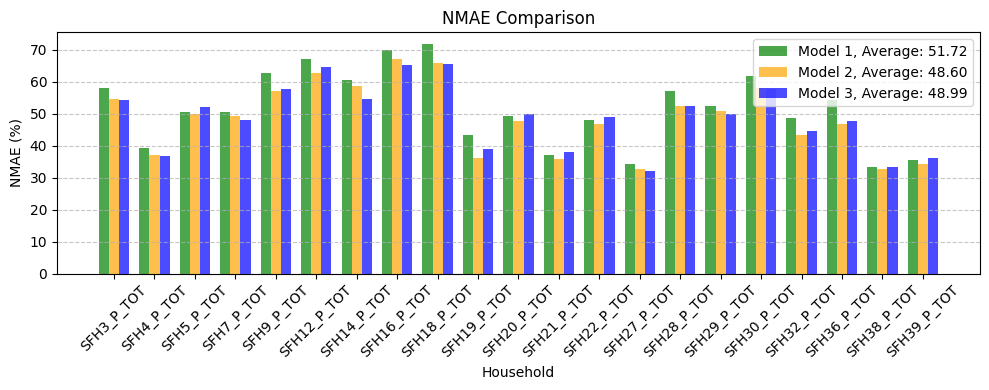

In [164]:
# Plot NMAEs
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
bar_width = 0.25
index = np.arange(len(nmae_results_m1.keys()))

plt.bar(index, nmae_results_m1.values(), bar_width, label=f'Model 1, Average: {nmae_average_m1:.2f}', color='green', alpha=0.7)
plt.bar(index + bar_width, nmae_results_m2.values(), bar_width, label=f'Model 2, Average: {nmae_average_m2:.2f}', color='orange', alpha=0.7)
plt.bar(index + 2 * bar_width, nmae_results_m3.values(), bar_width, label=f'Model 3, Average: {nmae_average_m3:.2f}', color='blue', alpha=0.7)

plt.xlabel('Household')
plt.ylabel('NMAE (%)')
plt.title('NMAE Comparison')
plt.xticks(index + bar_width, nmae_results_m1.keys(), rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



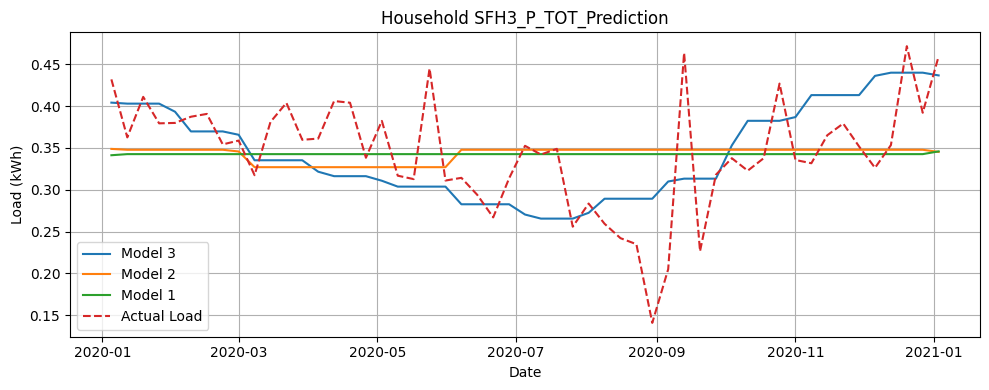

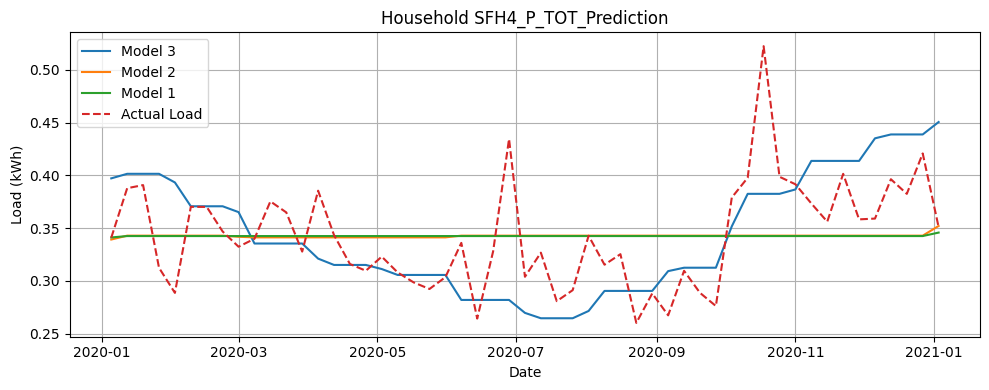

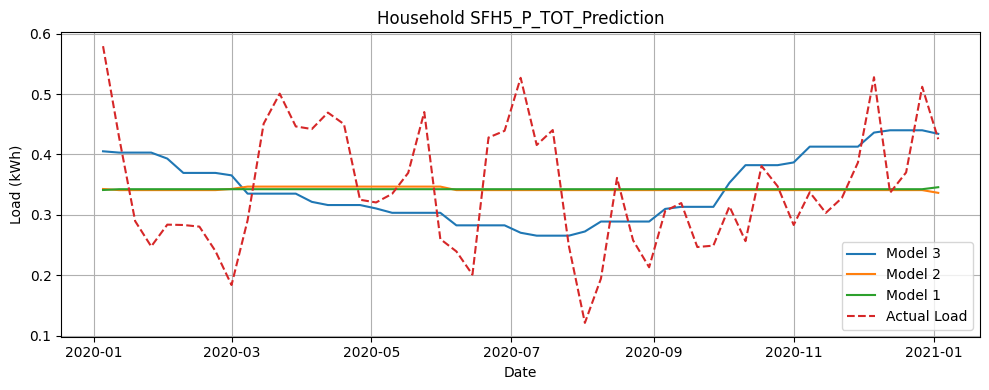

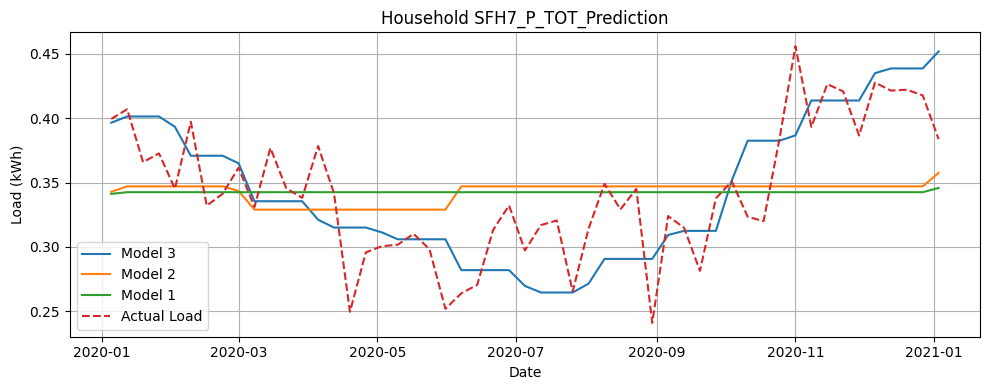

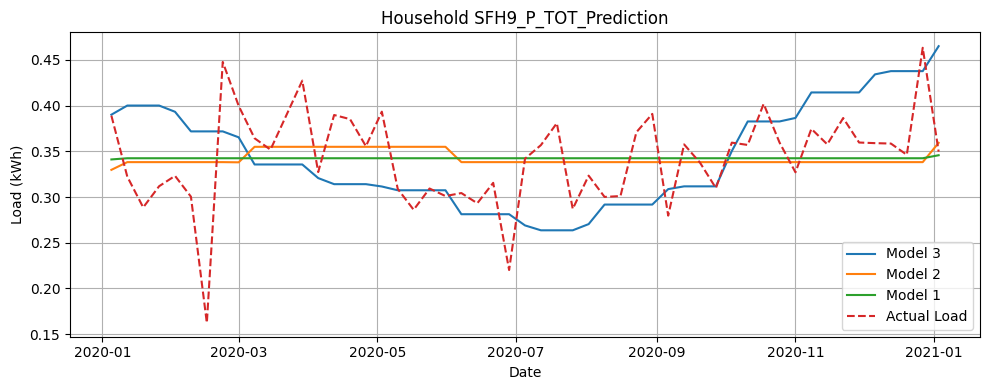

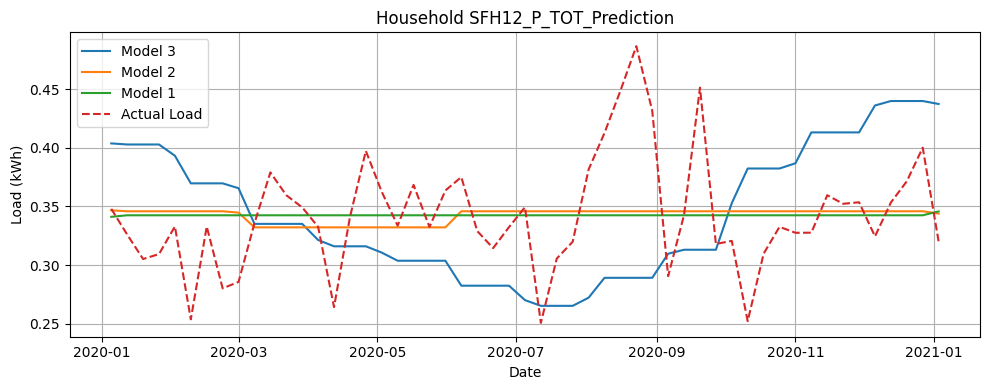

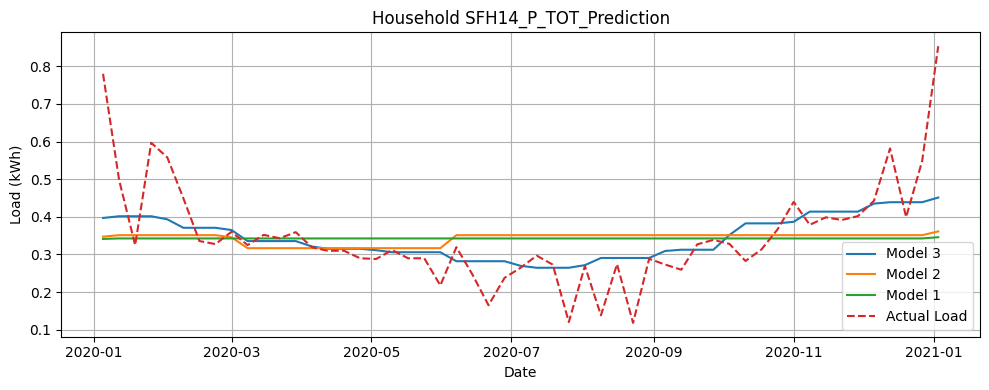

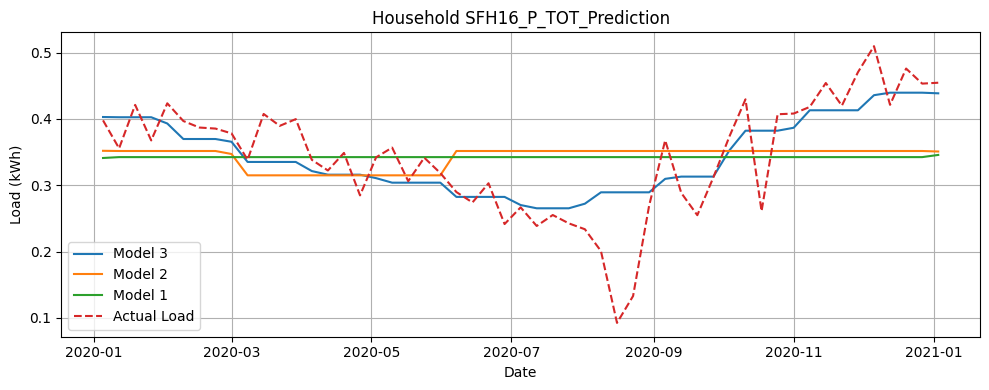

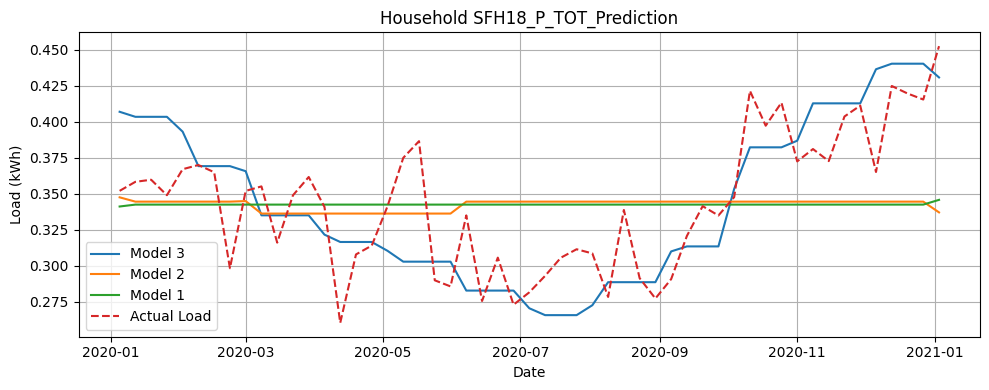

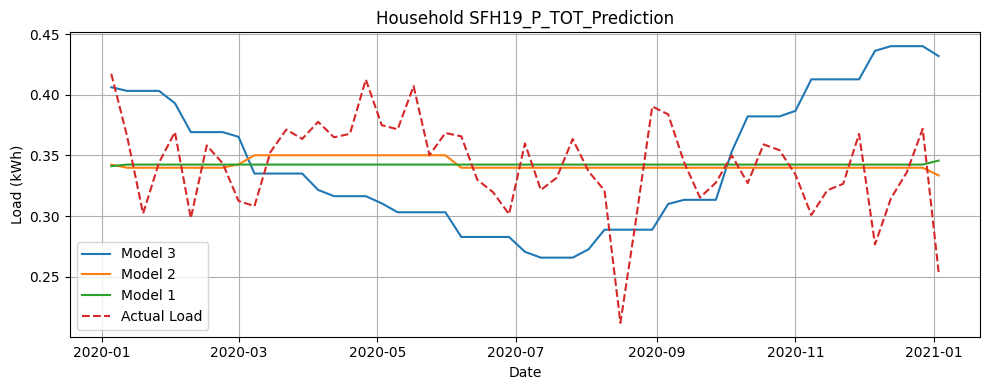

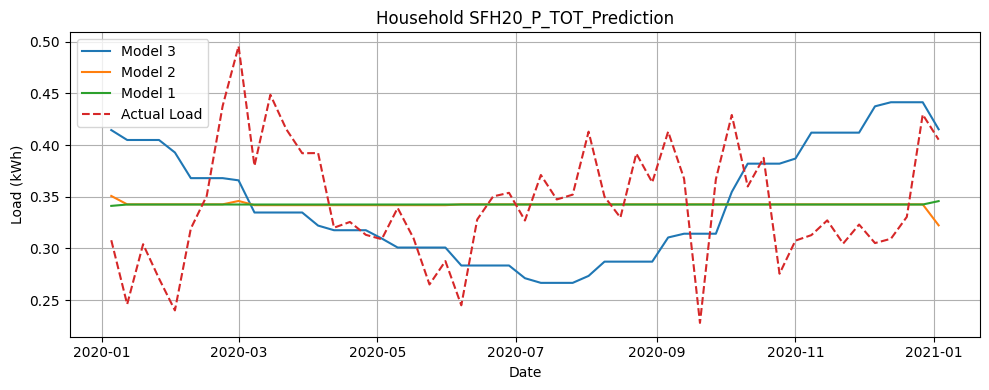

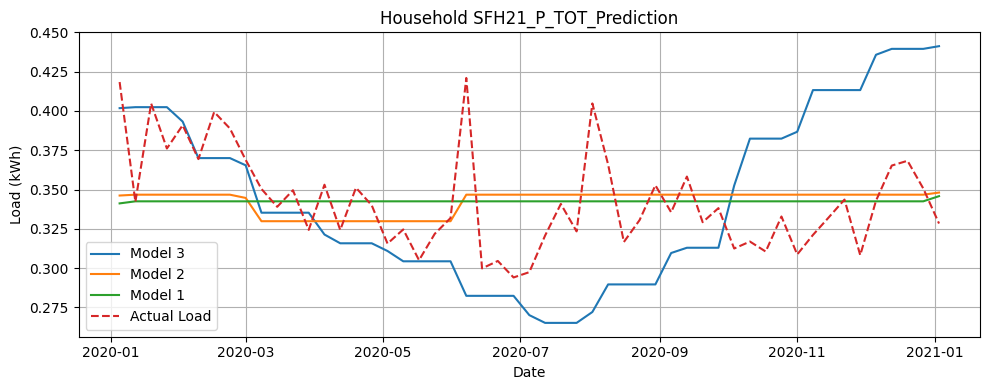

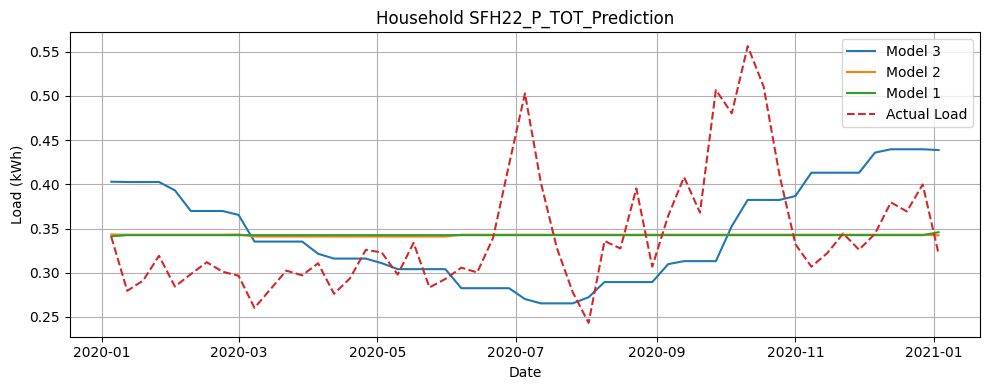

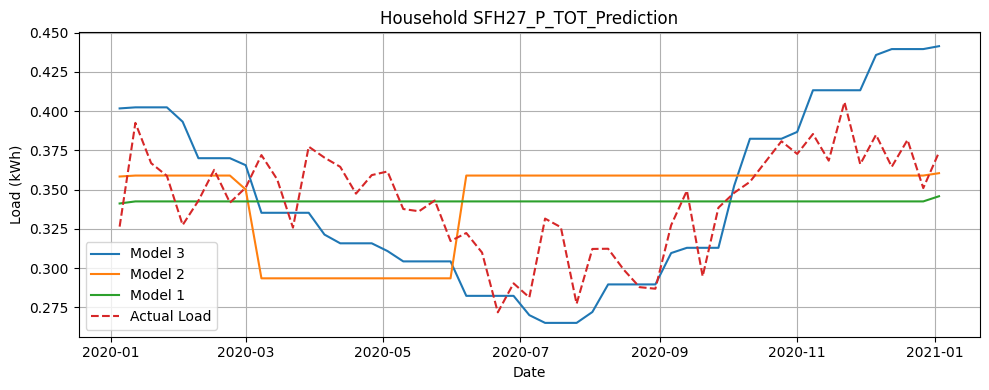

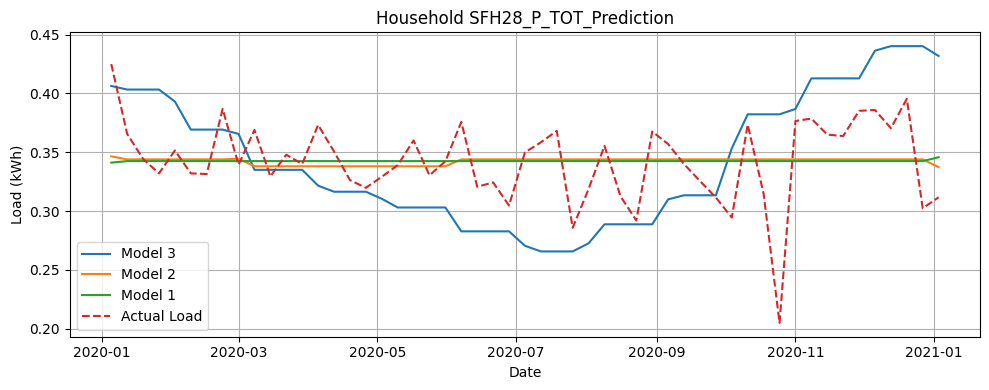

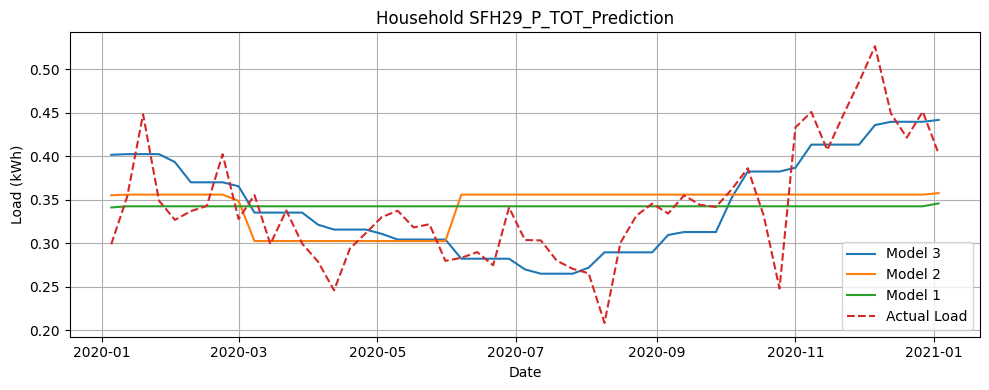

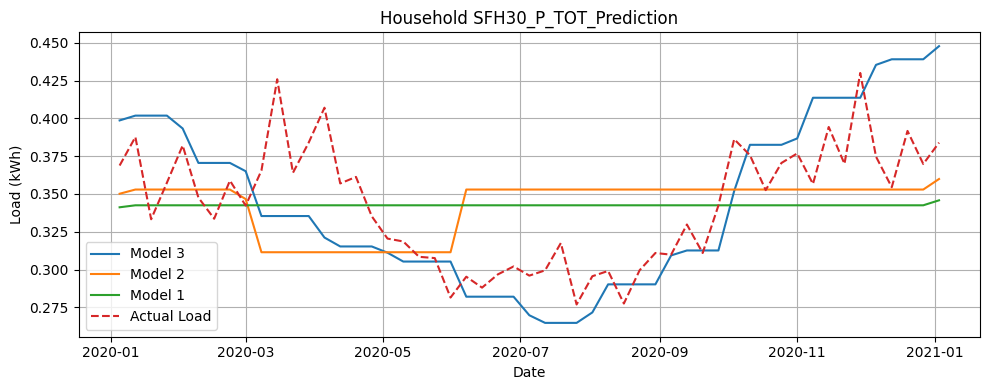

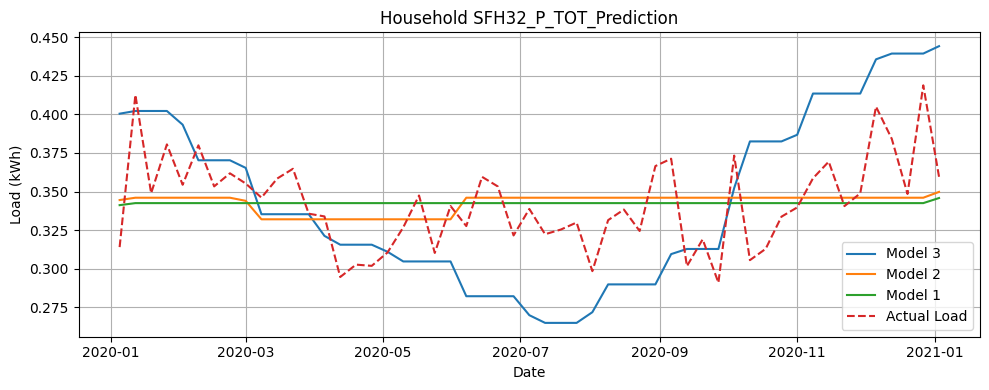

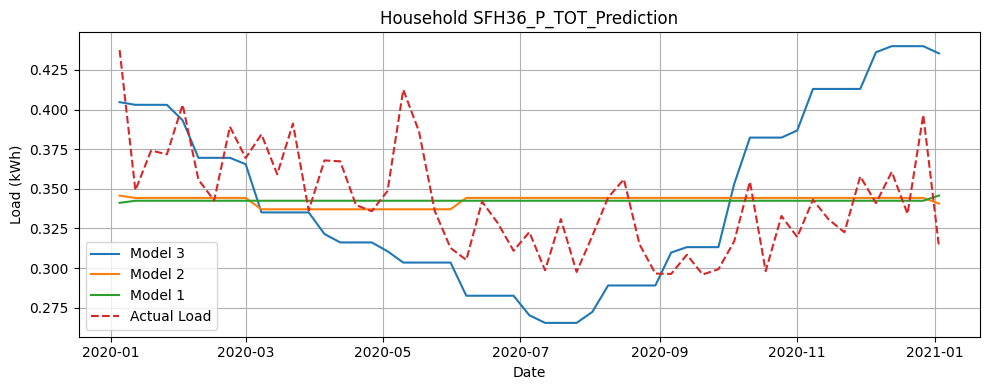

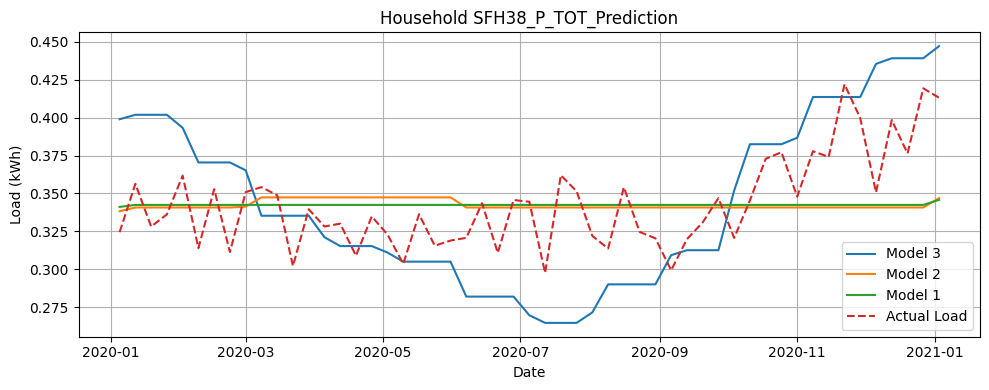

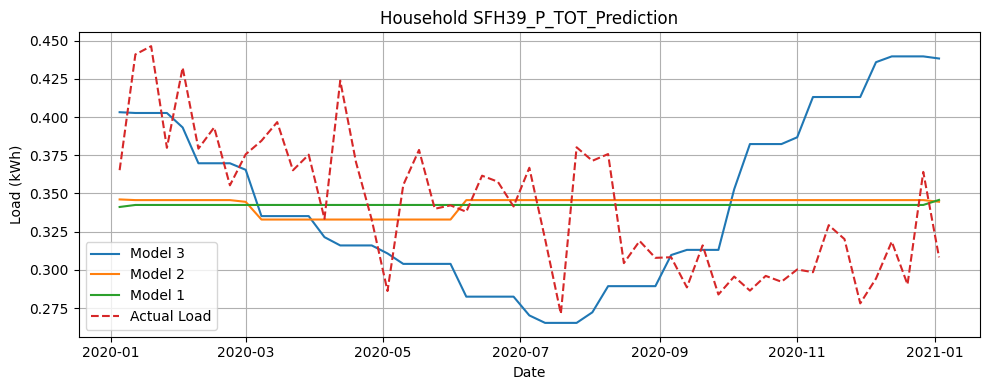

In [165]:
# smooth on weekly basis
model3_prediction_2020_weekly = model3_prediction_2020.resample('W').mean()
model2_prediction_2020_weekly = model2_prediction_2020.resample('W').mean()
model1_prediciton_2020_weekly = model1_prediciton_2020['H00_predicted [kWh]'].resample('W').mean()
actual_load_profile2020 = actual_load_profile2020.resample('W').mean()

# Plot Predicted Load Profile for 2020 for each household
for household in model3_prediction_2020_weekly.columns:
    plt.figure(figsize=(10, 4))
    plt.plot(model3_prediction_2020_weekly.index, model3_prediction_2020_weekly[household], label="Model 3")
    plt.plot(model2_prediction_2020_weekly.index, model2_prediction_2020_weekly[household], label="Model 2")
    plt.plot(model1_prediciton_2020_weekly.index, model1_prediciton_2020_weekly, label="Model 1")
    plt.plot(actual_load_profile2020.index, actual_load_profile2020[household.replace('_Prediction', '')], label="Actual Load", linestyle='--')
    plt.title(f'Household {household}')
    plt.xlabel('Date')
    plt.ylabel('Load (kWh)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# Dynamic Price Difference



Preise Plotten

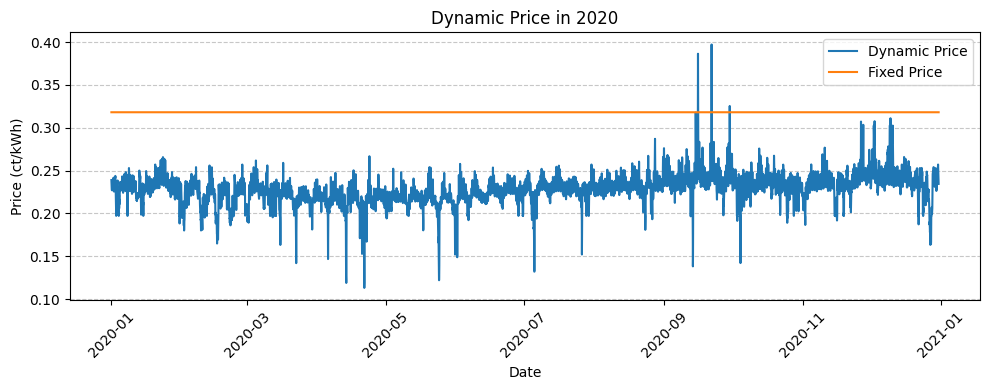

In [166]:
#plot dynamic_price_per_kwh_2020
plt.figure(figsize=(10,4))
plt.plot(dynamic_price_per_kwh_2020.index, dynamic_price_per_kwh_2020, label='Dynamic Price')
plt.plot(dynamic_price_per_kwh_2020.index, [0.3181]*len(dynamic_price_per_kwh_2020), label='Fixed Price')
plt.xlabel('Date')
plt.ylabel('Price (ct/kWh)')
plt.title('Dynamic Price in 2020')
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

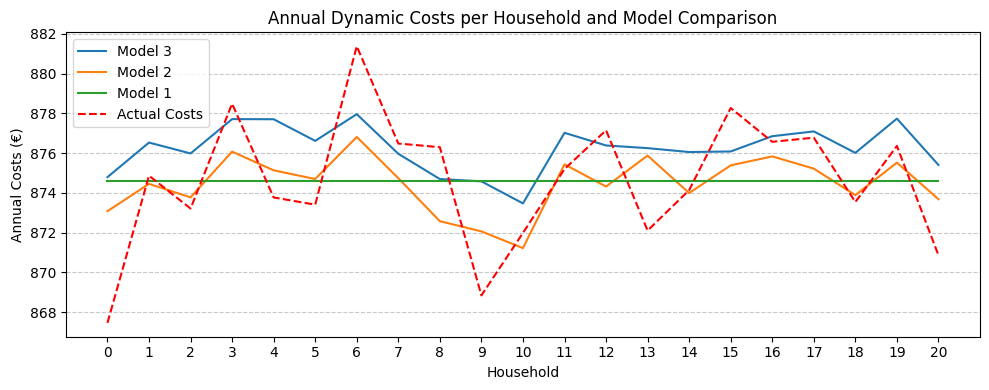

In [167]:
# Annual dynamic prices per Household and Model Comparison
dynamic_costs_allhouseholds_m3
dynamic_costs_allhouseholds_m2
dynamic_costs_allhouseholds_m1

#Plot values as table with numbers

plt.figure(figsize=(10,4))
plt.plot(dynamic_costs_allhouseholds_m3, label='Model 3')
plt.plot(dynamic_costs_allhouseholds_m2, label='Model 2')
plt.plot(dynamic_costs_allhouseholds_m1, label='Model 1')
plt.plot(dynamic_costs_allhouseholds_actual, label = 'Actual Costs', linestyle='--', color='red')
plt.xlabel('Household')
plt.xticks(np.arange(0, len(dynamic_costs_allhouseholds_actual), 1))
plt.ylabel('Annual Costs (€)')
plt.title('Annual Dynamic Costs per Household and Model Comparison')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()




# Write results in json datei

In [168]:
#Write results in json 

results = { 
     "Run Date": random_start_date.isoformat(),  # Konvertierung in einen String
    "NMAE": {
        "Model 1": nmae_results_m1,
        "Model 2": nmae_results_m2,
        "Model 3": nmae_results_m3
    },
    "Average NMAE": {
        "Model 1": nmae_average_m1,
        "Model 2": nmae_average_m2,
        "Model 3": nmae_average_m3
    },
    "Annual Predicted Costs": {
        "Model 1": dynamic_costs_allhouseholds_m1,
        "Model 2": dynamic_costs_allhouseholds_m2,
        "Model 3": dynamic_costs_allhouseholds_m3,
        "Static Prices": annual_predicted_costs_static_prices_results_m3,
        "Actual Costs": dynamic_costs_allhouseholds_actual
    }
}


# Schreibe die Daten in eine Datei namens "results.json"
with open("results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Die Ergebnisse wurden in results.json gespeichert.")

Die Ergebnisse wurden in results.json gespeichert.


# Write Load Forecast of Model 3 in /output_load

In [44]:
#Write Load Forecast of Model 3 in /output_load
model3_prediction_2020.to_csv('output_load/Load_Forecast_Model_3.csv')